<a href="https://colab.research.google.com/github/florenciazoni/proyecto-final-data-science-YPF/blob/main/grupo4_pre_entrega_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fundación YPF - Data Science

## Tercer pre entrega
Alumnas: Florencia Zoni, Virginia Contreras
### Clustering de jurisdicciones argentinas según su tasa de promoción efectiva (2012-2023)

### Índice de partes

* **Parte 0:** Preparación del entorno y objetivo
* **Parte 1:** Análisis exploratorio de datos (AED)
* **Parte 2:** Preparación de los datos
* **Parte 3:** Modelo base: K-Means
* **Parte 4:** Mejora del modelo y comparación de algoritmos
* **Parte 5:** Modelo final e interpretación de los clusters
* **Parte 6:** Conclusiones y limitaciones

## Parte 0: Preparación del entorno y objetivo
**Origen del dataset:** El dataset fue obtenido de la página de datos abiertos de Argentina (datos.gob.ar). Dentro de la misma se seleccionó educación como categoría de busqueda, información y calidad educativa llegando hasta indicadores de eficiencia. Las Tasas de Eficiencia Interna (Promoción, Repitencia, Abandono), Escolarización y Sobreedad son los temas principales, desagregados por nivel de enseñanza y jurisdicción. Nosotras tomamos promoción efectiva como dataset a estudiar, usando la tasa de promoción efectiva según división politico territorial 2012-2023. El archivo excel original presentaba cada año de estudio en una hoja distinta por lo cual hubo que tratar el mismo a fin de aunar los datos. Los datos originales son de la Secretaría de Educación de la Nación Argentina, Subsecrertaría de Evaluación e Información Educativa, Dirección Nacional de Información y Estadística Educativa.

**Pregunta que guía el trabajo:** ¿hay grupos de jurisdicciones con trayectorias escolares parecidas? Es decir, ¿se pueden agrupar las provincias según cómo promueven a sus estudiantes de un grado al siguiente?

**Dataset:** `Tasa_de_Promocion_Efectiva_2012-2023_unificada.xlsx`. Tiene la **tasa de promoción efectiva** (porcentaje de alumnos que pasan al grado siguiente) por jurisdicción, año y grado, para primaria y secundaria.

**Algoritmo elegido:** K-Means como modelo base, comparado después con clustering jerárquico y DBSCAN (el de la última clase) para justificar la elección.

**Criterio de decisión :** cada decisión se toma con tres criterios, en este orden:

1. **Calidad estadística:** coeficiente de silhouette (y Davies-Bouldin como control).
2. **Estabilidad:** que los grupos no cambien si cambia la semilla o el período de años usado.
3. **Interpretabilidad:** que los grupos se puedan describir y tengan sentido educativo.



In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
ARCHIVO = "Tasa_de_Promocion_Efectiva_2012-2023_unificada.xlsx"

if not os.path.exists(ARCHIVO):
    from google.colab import files
    files.upload()

df = pd.read_excel(ARCHIVO)

# Nombres cortos para trabajar más cómodos
df.columns = ["anio", "jur", "estructura",
              "Prim_Total", "Prim_1", "Prim_2", "Prim_3", "Prim_4", "Prim_5", "Prim_6", "Prim_7",
              "Sec_Total", "Sec_7", "Sec_8", "Sec_9", "Sec_10", "Sec_11", "Sec_12"]
df.head()

Saving Tasa_de_Promocion_Efectiva_2012-2023_unificada.xlsx to Tasa_de_Promocion_Efectiva_2012-2023_unificada.xlsx


,anio,jur,estructura,Prim_Total,Prim_1,Prim_2,Prim_3,Prim_4,Prim_5,Prim_6,Prim_7,Sec_Total,Sec_7,Sec_8,Sec_9,Sec_10,Sec_11,Sec_12
0,2023,Buenos Aires,6-6,97.0422,100.6889,94.6829,95.3455,96.3991,96.7931,98.7196,NaN,87.0482,93.7906,89.2891,89.2842,81.5682,85.2882,80.8773
1,2023,Catamarca,6-6,98.8454,100.5482,99.5467,97.6836,99.0491,97.9604,98.3532,NaN,88.0095,93.3128,87.4566,86.7855,85.4326,92.1219,81.8006
2,2023,Chaco,7-5,97.7121,99.4323,98.8346,96.2084,98.2575,96.6791,97.0723,97.6521,77.2890,NaN,80.5473,76.4445,76.8003,78.6136,72.4957
3,2023,Chubut,6-6,99.6969,99.7519,99.7665,99.5723,99.2248,99.8922,99.9799,NaN,86.3467,90.4766,87.1913,86.4412,82.9968,84.3292,85.5093
4,2023,Ciudad de Buenos Aires,7-5,98.3077,98.8849,97.2360,97.5947,97.8824,97.5986,99.2355,99.7380,88.2758,NaN,98.5944,87.1759,86.8790,89.5332,78.0001


## Parte 1: Análisis exploratorio de datos (AED)


### 1.1 Estructura general

In [3]:
print("Filas y columnas:", df.shape)
print("Años:", df.anio.min(), "a", df.anio.max())
print("Unidades por año:", df.groupby("anio").size().unique())
print("Unidades distintas:", df.jur.nunique())
print()
print(sorted(df.jur.unique()))

Filas y columnas: (324, 18)
Años: 2012 a 2023
Unidades por año: [27]
Unidades distintas: 27

['Buenos Aires', 'Catamarca', 'Chaco', 'Chubut', 'Ciudad de Buenos Aires', 'Conurbano', 'Cordoba', 'Corrientes', 'Entre Rios', 'Formosa', 'Jujuy', 'La Pampa', 'La Rioja', 'Mendoza', 'Misiones', 'Neuquén', 'Resto de Bs As', 'Rio Negro', 'Salta', 'San Juan', 'San Luis', 'Santa Cruz', 'Santa Fe', 'Santiago Del Estero', 'Tierra Del Fuego', 'Total País', 'Tucumán']


Hay 27 unidades por año. Pero **no todas son provincias**: aparecen `Total País`, `Conurbano` y `Resto de Bs As`, que son agregados y se superponen con `Buenos Aires`. Si las dejáramos, estaríamos contando dos veces a los mismos alumnos. Esto lo resolvemos en la Parte 2.

### 1.2 Nulos

In [4]:
nulos = df.isna().sum()
print(nulos[nulos > 0])
print()
# ¿Los nulos de Prim_7 y Sec_7 dependen de la estructura educativa?
df["falta"] = np.where(df.Prim_7.isna() & df.Sec_7.notna(), "Prim_7 vacío",
              np.where(df.Sec_7.isna() & df.Prim_7.notna(), "Sec_7 vacío", "otro"))
print(pd.crosstab(df.estructura.fillna("sin dato"), df.falta))
df = df.drop(columns="falta")

estructura     12
Prim_7        168
Sec_7         144
dtype: int64

falta       Prim_7 vacío  Sec_7 vacío  otro
estructura                                 
6-6                  168            0     0
7-5                    0          144     0
sin dato               0            0    12


Los nulos **no son datos perdidos**, son **nulos estructurales**: en las jurisdicciones con estructura **6-6** no existe 7° de primaria, y en las **7-5** no existe 7° de secundaria. Imputarlos con la media sería inventar datos de un grado que no existe.

**Decisión 1:** trabajamos solo con los grados que existen en todas las jurisdicciones: **1° a 6° de primaria** y **8° a 12° de secundaria** (11 variables, sin nulos estructurales).

### 1.3 Valores mayores a 100

In [5]:
numericas = df.select_dtypes("number").drop(columns="anio")
print((numericas > 100).sum())
print()
print("Máximo observado:", round(float(numericas.max().max()), 2))

Prim_Total     12
Prim_1        124
Prim_2         35
Prim_3         13
Prim_4         18
Prim_5         12
Prim_6         18
Prim_7         12
Sec_Total       0
Sec_7           1
Sec_8           2
Sec_9           4
Sec_10          2
Sec_11          2
Sec_12          0
dtype: int64

Máximo observado: 102.28


Una "tasa" de 102% parece un error, pero es posible: la promoción efectiva compara alumnos que **pasan de grado** con la matrícula del grado de origen, y puede superar 100 por reingresos o alumnos que se incorporan desde otras jurisdicciones o desde el sistema no estatal. Son desvíos chicos, y se concentran en 1° de primaria.

**Decisión 2:** **no los recortamos a 100**. Son una característica real de la fuente y el recorte distorsionaría diferencias entre jurisdicciones. Lo dejamos documentado como limitación.

### 1.4 Distribución por grado

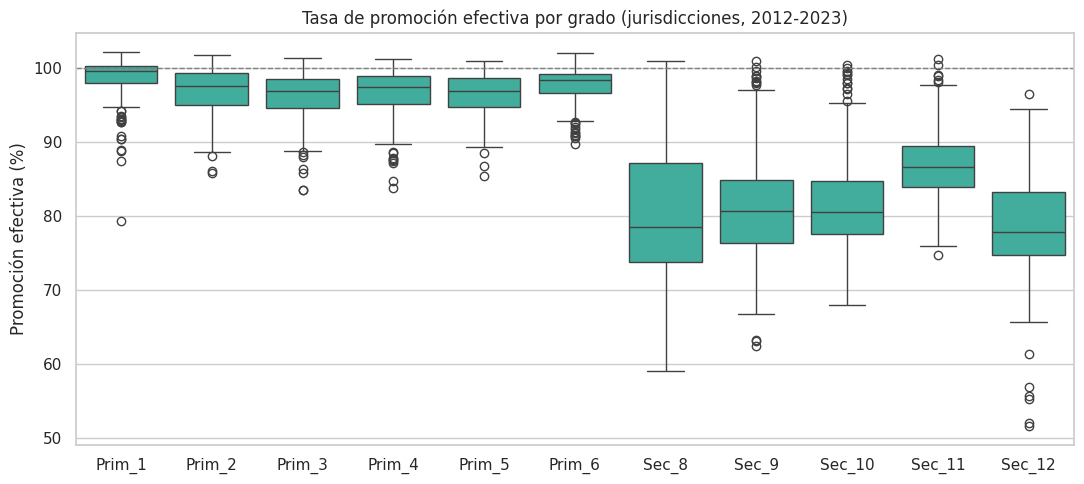

In [6]:
grados = ["Prim_1", "Prim_2", "Prim_3", "Prim_4", "Prim_5", "Prim_6", "Sec_8", "Sec_9", "Sec_10", "Sec_11", "Sec_12"]
agregados = ["Total País", "Conurbano", "Resto de Bs As"]
d = df[~df.jur.isin(agregados)]

plt.figure(figsize=(11, 5))
sns.boxplot(data=d[grados], color="#30BEAA")
plt.axhline(100, color="gray", linestyle="--", linewidth=1)
plt.title("Tasa de promoción efectiva por grado (jurisdicciones, 2012-2023)")
plt.ylabel("Promoción efectiva (%)")
plt.tight_layout()
plt.show()

La primaria está concentrada cerca de 95-100%, con poca variación. La secundaria tiene **medianas más bajas y mucha más dispersión**: ahí es donde las jurisdicciones se diferencian. Esto anticipa que la secundaria va a ser la que más pese en la separación de grupos.

### 1.5 Evolución en el tiempo

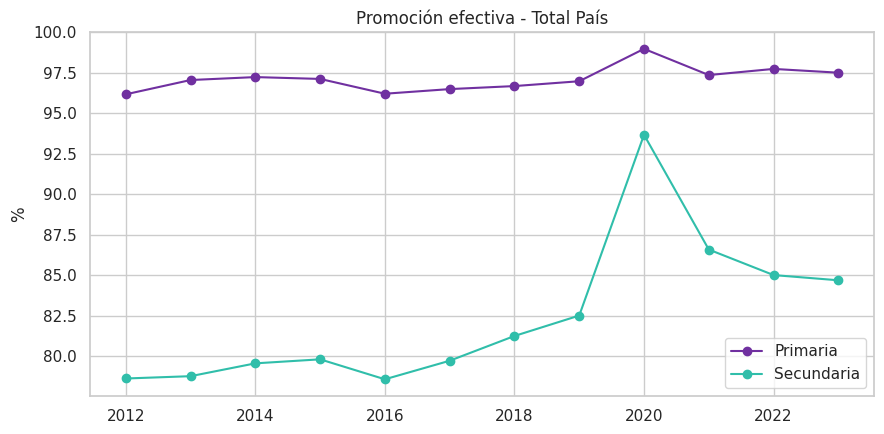

In [7]:
pais = df[df.jur == "Total País"].set_index("anio")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(pais.index, pais.Prim_Total, marker="o", color="#7030A0", label="Primaria")
ax.plot(pais.index, pais.Sec_Total, marker="o", color="#30BEAA", label="Secundaria")
ax.set_title("Promoción efectiva - Total País")
ax.set_ylabel("%")
ax.legend()
plt.tight_layout()
plt.show()

En primaria, el total país se mantiene entre 96% y 99% durante todo el período. En secundaria, la promoción ronda **79%-83% entre 2012 y 2019**, pega un **pico de 93.7% en 2020** y después se estabiliza en torno a **85%-87%**, por encima del nivel previo. El 2020 es un año atípico (pandemia y criterios de promoción especiales). Esa explicación es contextual: los datos muestran el salto, pero no prueban su causa.

**Decisión 3:** para describir a cada jurisdicción usamos el **promedio 2012-2023** de cada grado: queremos agrupar por comportamiento *típico*, no por un año puntual. Más adelante (Parte 4) verificamos que los grupos no dependan de qué años se usan, porque 2020-2021 fueron años atípicos.

### 1.6 Correlaciones entre grados

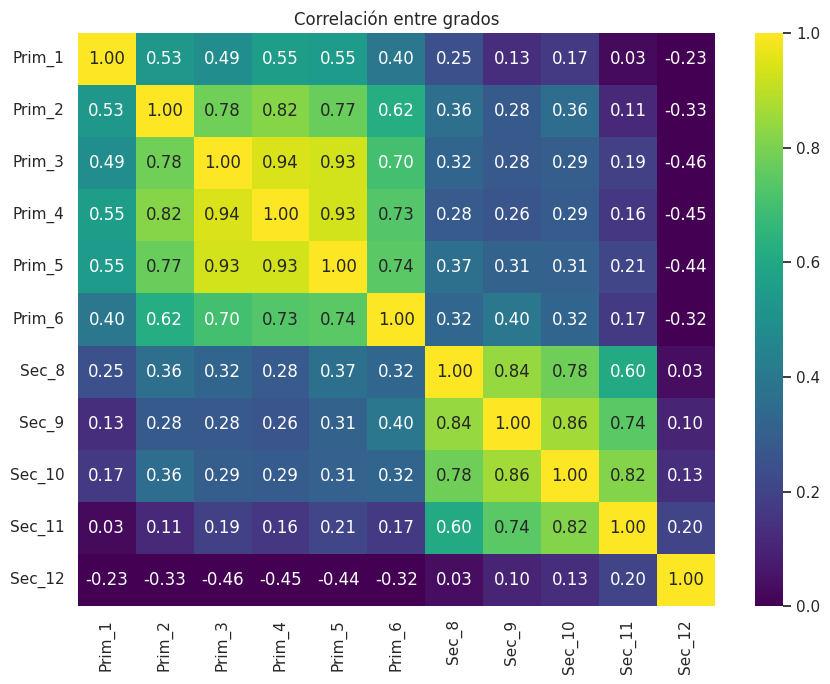

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(d[grados].corr(), annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Correlación entre grados")
plt.tight_layout()
plt.show()

Dos hallazgos que van a guiar las decisiones de más adelante:

* **Primaria repite información:** los grados 2° a 5° están correlacionados entre 0.77 y 0.94. Es casi la misma columna copiada varias veces.
* **12° año se comporta distinto:** casi no se correlaciona con 8° a 11° (entre 0.03 y 0.20) y tiene correlación **negativa** con primaria (entre -0.23 y -0.46).
* Primaria y secundaria (8° a 11°) se correlacionan poco entre sí (hasta 0.40): que una jurisdicción tenga buena primaria no garantiza una buena secundaria.

### 1.7 Ranking de jurisdicciones

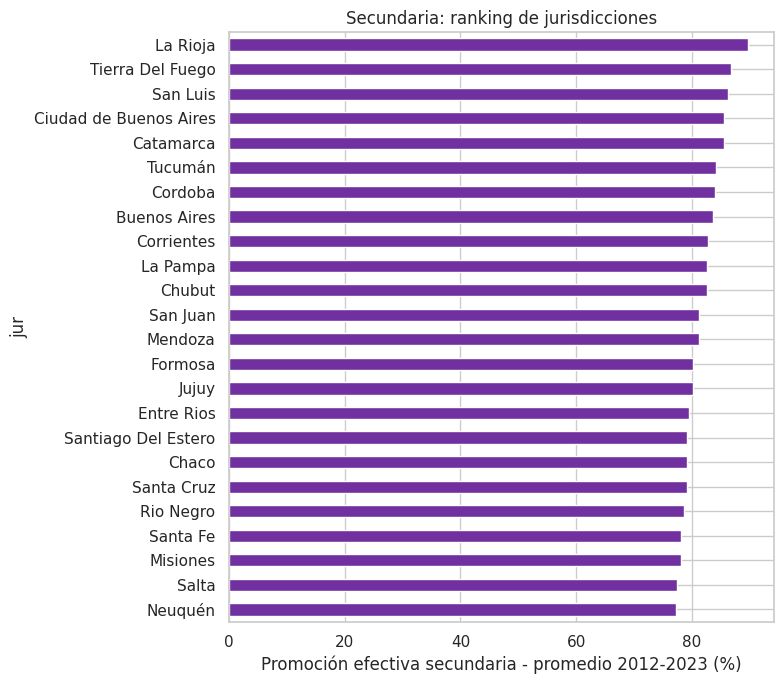

In [9]:
perfil = d.groupby("jur")[grados].mean()
orden = perfil.Sec_Total if "Sec_Total" in perfil else d.groupby("jur").Sec_Total.mean()
orden = d.groupby("jur").Sec_Total.mean().sort_values()

plt.figure(figsize=(8, 7))
orden.plot(kind="barh", color="#7030A0")
plt.xlabel("Promoción efectiva secundaria - promedio 2012-2023 (%)")
plt.title("Secundaria: ranking de jurisdicciones")
plt.tight_layout()
plt.show()

En secundaria, el promedio va de **77.3%** (Neuquén) a **89.7%** (La Rioja): unos 12 puntos de diferencia entre extremos. En primaria las diferencias son mucho menores: la más baja es Corrientes (91.0%) y las siguientes rondan el 94%. Hay grupos por descubrir, y la secundaria es donde más se diferencian.

## Parte 2: Preparación de los datos

Resumimos lo decidido en el AED y armamos la matriz final.

| Decisión | Qué hacemos | Por qué |
|---|---|---|
| Agregados | Excluimos `Total País`, `Conurbano` y `Resto de Bs As` | Se superponen con `Buenos Aires` |
| Nulos estructurales | Usamos solo grados 1-6 y 8-12 | 7° no existe en todas las estructuras |
| Valores > 100 | Se mantienen | Son reales en la fuente |
| Unidad de análisis | Una fila por jurisdicción (promedio 2012-2023) | Buscamos comportamiento típico |
| Escala | `StandardScaler` | K-Means y DBSCAN usan distancias |

In [10]:
perfil = d.groupby("jur")[grados].mean()
print("Matriz de trabajo:", perfil.shape, "(jurisdicciones x grados)")

X = StandardScaler().fit_transform(perfil)
perfil.round(1).head()

Matriz de trabajo: (24, 11) (jurisdicciones x grados)


,Prim_1,Prim_2,Prim_3,Prim_4,Prim_5,Prim_6,Sec_8,Sec_9,Sec_10,Sec_11,Sec_12
jur,,,,,,,,,,,
Buenos Aires,100.2,95.4,95.9,96.6,96.7,98.9,81.5,86.6,79.8,84.1,79.1
Catamarca,99.5,97.7,96.9,97.4,97.1,98.0,83.0,85.8,85.6,88.8,80.9
Chaco,98.9,97.1,94.9,95.7,95.5,94.8,76.3,77.0,81.2,86.1,78.0
Chubut,100.2,98.4,98.2,98.2,97.9,99.5,81.5,83.2,79.8,85.1,78.6
Ciudad de Buenos Aires,98.7,97.4,97.8,97.9,98.0,98.5,88.0,85.6,86.5,88.4,78.3


Nos quedan **24 jurisdicciones y 11 variables**. Es un dataset chico: con tan pocos puntos tenemos que ser cuidadosos con las conclusiones, y por eso en la Parte 4 incluimos pruebas de estabilidad.

## Parte 3: Modelo base: K-Means

### 3.1 Elegir k

Probamos k de 2 a 8 y miramos tres métricas: la **inercia** (método del codo), el **silhouette** (cuánto más cerca está cada punto de su grupo que del grupo vecino; más alto es mejor) y **Davies-Bouldin** (más bajo es mejor).

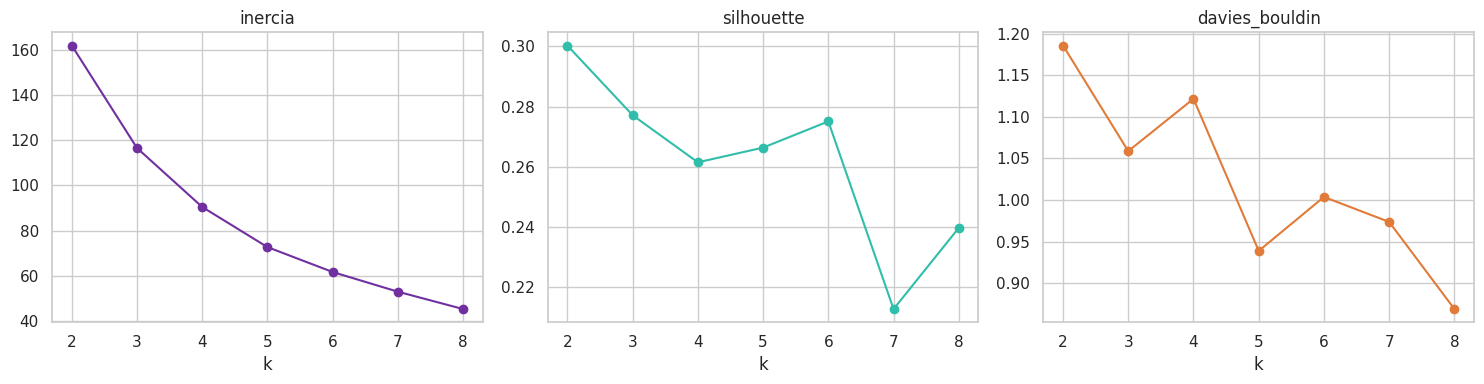

,inercia,silhouette,davies_bouldin
k,,,
2,161.973,0.300,1.186
3,116.589,0.277,1.059
4,90.469,0.261,1.122
5,72.712,0.266,0.939
6,61.680,0.275,1.004
7,52.963,0.213,0.974
8,45.278,0.240,0.869


In [11]:
resultados = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    resultados.append({"k": k,
                       "inercia": km.inertia_,
                       "silhouette": silhouette_score(X, km.labels_),
                       "davies_bouldin": davies_bouldin_score(X, km.labels_)})
res_k = pd.DataFrame(resultados).set_index("k")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, color in zip(ax, ["inercia", "silhouette", "davies_bouldin"], ["#7030A0", "#30BEAA", "#E07B39"]):
    a.plot(res_k.index, res_k[col], marker="o", color=color)
    a.set_title(col)
    a.set_xlabel("k")
plt.tight_layout()
plt.show()

res_k.round(3)

* **Inercia:** baja de forma pareja y **no hay un codo claro**, así que no alcanza para decidir.
* **Silhouette:** el máximo está en k=2 (0.300) y k=3 es el segundo (0.277). Son valores bajos en todos los casos (menores a 0.30): los grupos **no están muy separados**, se parecen más a un continuo con tendencias.
* **Davies-Bouldin:** k=3 (1.059) es mejor que k=2 (1.186).

**Decisión: k = 3.** k=2 solo separaría "mejores" y "peores", que es poco informativo, y su ventaja en silhouette es chica (0.02). k=3 mejora Davies-Bouldin y permite describir perfiles distintos. Desde k=4 el silhouette baja.

### 3.2 Modelo base con el k elegido

In [12]:
K_BASE = 3
km_base = KMeans(n_clusters=K_BASE, n_init=10, random_state=RANDOM_STATE).fit(X)
perfil["cluster_base"] = km_base.labels_

print("Silhouette:", round(silhouette_score(X, km_base.labels_), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X, km_base.labels_), 3))
print()
print(perfil.cluster_base.value_counts().sort_index())

Silhouette: 0.277
Davies-Bouldin: 1.059

cluster_base
0     7
1     7
2    10
Name: count, dtype: int64


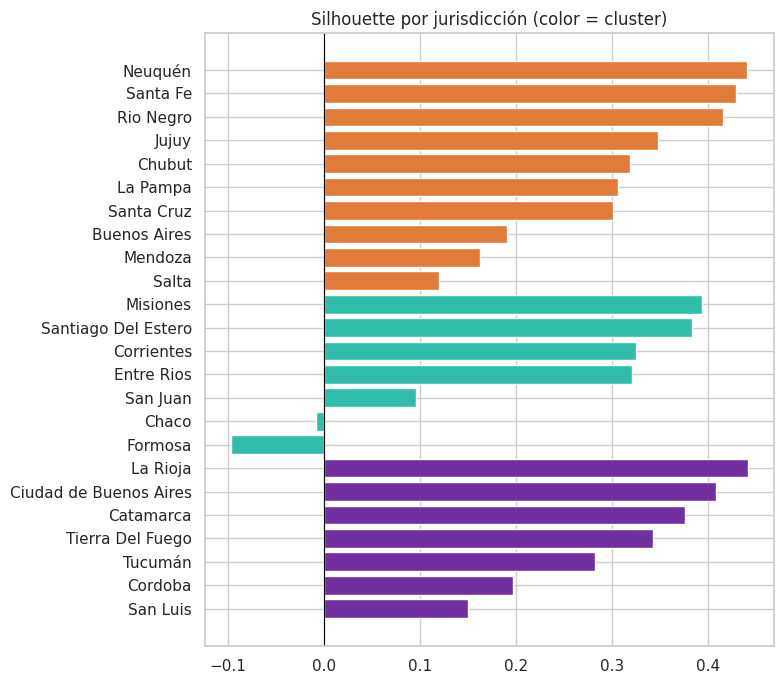

In [13]:
# Silhouette por jurisdicción: ¿hay jurisdicciones mal asignadas (valores negativos)?
perfil["silhouette"] = silhouette_samples(X, km_base.labels_)

plt.figure(figsize=(8, 7))
orden_sil = perfil.sort_values(["cluster_base", "silhouette"])
colores = orden_sil.cluster_base.map({0: "#7030A0", 1: "#30BEAA", 2: "#E07B39"})
plt.barh(orden_sil.index, orden_sil.silhouette, color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Silhouette por jurisdicción (color = cluster)")
plt.tight_layout()
plt.show()

El silhouette global (0.277) es bajo, y el gráfico lo confirma: **Chaco (-0.01) y Formosa (-0.10)** tienen silhouette nulo o negativo (están tan cerca de otro grupo como del propio, o más) y San Juan ronda 0.10. Los grupos del modelo base **no son nítidos**. Es un buen punto de partida, pero hay margen de mejora.

## Parte 4: Mejora del modelo y comparación de algoritmos

El modelo base es un punto de partida. Probamos mejoras y las juzgamos con el criterio de la Parte 0 (calidad, estabilidad e interpretabilidad). Para que la comparación sea justa, **todas las métricas de calidad que comparan variantes se calculan también sobre el mismo espacio original** (`X`), porque un silhouette calculado en espacios distintos no es directamente comparable.

### 4.1 Mejora A: PCA

En el AED vimos que los grados de primaria están muy correlacionados entre sí. PCA resume esa información repetida en pocos componentes. Probamos si eso mejora los grupos.

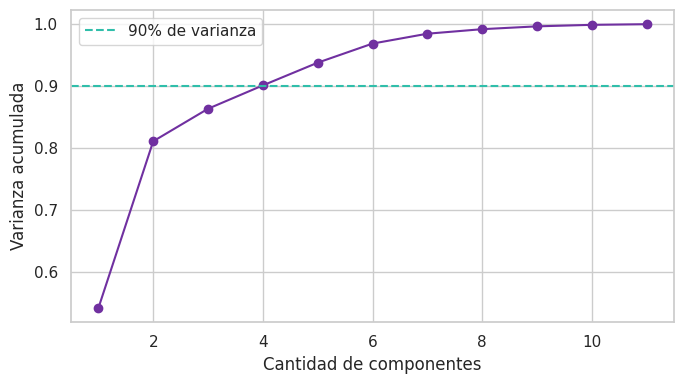

Componentes para explicar al menos 90% de la varianza: 4
Varianza explicada por componente: [0.541 0.27  0.053 0.038 0.037]


In [14]:
pca = PCA().fit(X)
var_acum = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(var_acum) + 1), var_acum, marker="o", color="#7030A0")
plt.axhline(0.9, color="#30BEAA", linestyle="--", label="90% de varianza")
plt.xlabel("Cantidad de componentes")
plt.ylabel("Varianza acumulada")
plt.legend()
plt.tight_layout()
plt.show()

n_comp = int(np.argmax(var_acum >= 0.90) + 1)
print("Componentes para explicar al menos 90% de la varianza:", n_comp)
print("Varianza explicada por componente:", np.round(pca.explained_variance_ratio_[:5], 3))

In [15]:
X_pca = PCA(n_components=n_comp, random_state=RANDOM_STATE).fit_transform(X)

filas = []
for k in range(2, 7):
    for nombre, M in [("K-Means sobre variables originales", X), ("K-Means sobre PCA", X_pca)]:
        etiq = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(M)
        filas.append({"k": k, "modelo": nombre, "silhouette (espacio original)": silhouette_score(X, etiq)})

pd.DataFrame(filas).pivot(index="k", columns="modelo", values="silhouette (espacio original)").round(3)

modelo,K-Means sobre PCA,K-Means sobre variables originales
k,,
2,0.300,0.300
3,0.277,0.277
4,0.265,0.261
5,0.269,0.266
6,0.251,0.275


**PCA no mejora nada:** con 4 componentes (90% de la varianza) el silhouette medido en el espacio original da lo mismo que sin PCA (k=3: 0.277 en ambos). Los dos primeros componentes explican 54% y 27% de la varianza, pero son combinaciones de grados difíciles de explicar. **Descartamos PCA como mejora** y lo usamos solo para graficar en 2 dimensiones.

### 4.2 Mejora B: resumir las variables redundantes

La idea es la misma que PCA pero **controlada por nosotros y con significado educativo**: en vez de 6 columnas casi iguales de primaria, usamos **una sola** (su promedio). En secundaria agrupamos 8° a 10° (los tres grados que se comportan parecido) y dejamos **11° y 12° por separado**, porque 12° es el año de egreso y tiene un nivel distinto al resto.

Así pasamos de 11 variables a **4**, y primaria deja de pesar 6 veces.

In [16]:
def resumir(g):
    return pd.DataFrame({
        "Primaria (prom. 1°-6°)": g[["Prim_1", "Prim_2", "Prim_3", "Prim_4", "Prim_5", "Prim_6"]].mean(axis=1),
        "Sec. 8°-10° (prom.)": g[["Sec_8", "Sec_9", "Sec_10"]].mean(axis=1),
        "Sec. 11°": g["Sec_11"],
        "Sec. 12°": g["Sec_12"],
    })

perfil_r = resumir(perfil[grados])
X_r = StandardScaler().fit_transform(perfil_r)

filas = []
for k in range(2, 7):
    etiq = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_r)
    filas.append({"k": k,
                  "silhouette (variables resumidas)": silhouette_score(X_r, etiq),
                  "silhouette (espacio original)": silhouette_score(X, etiq),
                  "davies_bouldin": davies_bouldin_score(X_r, etiq)})
res_k_r = pd.DataFrame(filas).set_index("k")
res_k_r.round(3)

,silhouette (variables resumidas),silhouette (espacio original),davies_bouldin
k,,,
2,0.332,0.215,1.079
3,0.379,0.269,0.892
4,0.264,0.261,1.138
5,0.296,0.172,1.022
6,0.286,0.177,0.992


Con las 4 variables, **k=3 pasa a ser claramente el mejor**: silhouette 0.379 (contra 0.332 en k=2 y 0.264 en k=4) y el Davies-Bouldin más bajo (0.892). Esto confirma la elección de k=3 con otro criterio.

**Ojo con la comparación:** ese 0.379 se mide en un espacio de 4 variables, así que no es directamente comparable con el 0.277 del modelo base. Por eso lo medimos también en el espacio original: da **0.269**, casi igual al base (0.277). Es decir, la mejora **no está en separar más los grupos**, sino en que sean **más estables e interpretables**. Lo comprobamos en 4.4.

### 4.3 Mejora C: comparar algoritmos sobre las variables resumidas

Comparamos K-Means con **clustering jerárquico (Ward)** y **DBSCAN** (visto en la clase anterior), todos sobre `X_r`. Para DBSCAN elegimos `eps` con el gráfico de distancias, como en clase, pero con `min_samples = 3` porque tenemos solo 24 puntos.

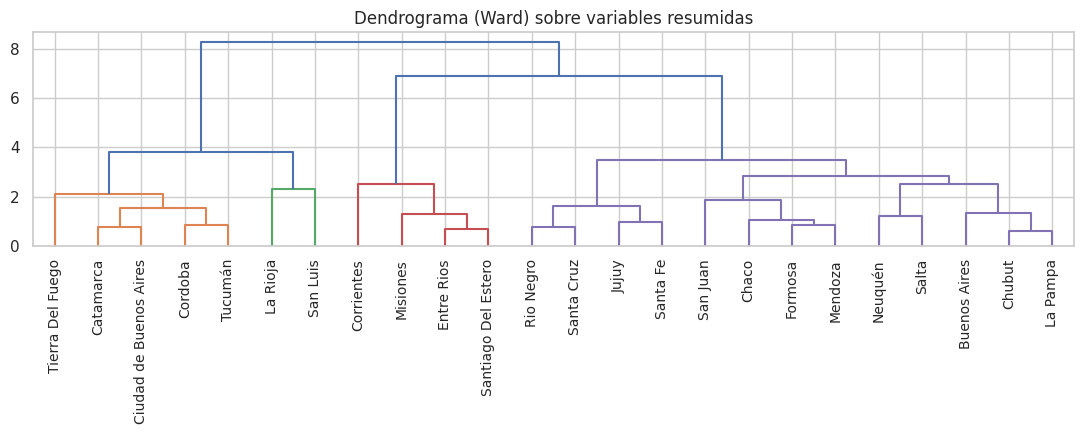

In [17]:
Z = linkage(X_r, method="ward")
plt.figure(figsize=(11, 4.5))
dendrogram(Z, labels=perfil_r.index.tolist(), leaf_rotation=90, color_threshold=Z[-3, 2])
plt.title("Dendrograma (Ward) sobre variables resumidas")
plt.tight_layout()
plt.show()

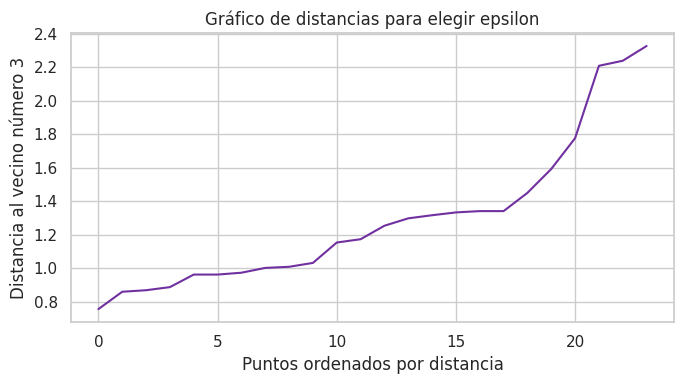

,eps,clusters,ruido
0,0.4,0,24
1,0.6,0,24
2,0.8,1,21
3,1.0,3,11
4,1.2,4,6
5,1.5,3,3


In [18]:
min_samples = 3
dist, _ = NearestNeighbors(n_neighbors=min_samples).fit(X_r).kneighbors(X_r)
dist_k = np.sort(dist[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(dist_k, color="#7030A0")
plt.xlabel("Puntos ordenados por distancia")
plt.ylabel(f"Distancia al vecino número {min_samples}")
plt.title("Gráfico de distancias para elegir epsilon")
plt.tight_layout()
plt.show()

filas = []
for eps in [0.4, 0.6, 0.8, 1.0, 1.2, 1.5]:
    etiq = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_r)
    filas.append({"eps": eps,
                  "clusters": len(set(etiq)) - (1 if -1 in etiq else 0),
                  "ruido": int((etiq == -1).sum())})
pd.DataFrame(filas)

In [19]:
K_FINAL = 3
etiq_km = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit_predict(X_r)
etiq_ward = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit_predict(X_r)
etiq_db = DBSCAN(eps=1.5, min_samples=min_samples).fit_predict(X_r)

def sil_sin_ruido(etiq):
    mask = etiq != -1
    if len(set(etiq[mask])) < 2:
        return np.nan
    return silhouette_score(X_r[mask], etiq[mask])

modelos = [etiq_km, etiq_ward, etiq_db]
comparacion = pd.DataFrame({
    "clusters": [len(set(e)) - (1 if -1 in e else 0) for e in modelos],
    "ruido": [int((e == -1).sum()) for e in modelos],
    "silhouette (sin ruido)": [sil_sin_ruido(e) for e in modelos],
    "ARI vs K-Means": [adjusted_rand_score(etiq_km, e) for e in modelos],
}, index=["K-Means", "Jerárquico (Ward)", f"DBSCAN (eps={1.5})"]).round(3)
comparacion

,clusters,ruido,silhouette (sin ruido),ARI vs K-Means
K-Means,3,0,0.379,1.000
Jerárquico (Ward),3,0,0.375,0.789
DBSCAN (eps=1.5),3,3,0.383,0.759


* **Los tres algoritmos coinciden bastante** (ARI de 0.79 entre K-Means y Ward, 0.76 entre K-Means y DBSCAN): la estructura de 3 grupos no es un invento de K-Means.
* **DBSCAN es frágil con tan pocos puntos.** Con eps = 0.6 o menos todo es ruido, con eps = 1.0 hay 11 de 24 jurisdicciones como ruido, y recién con eps = 1.5 (el valor más favorable de la tabla) queda con 3 ruidos. Aun así arma grupos de tamaños muy desparejos (13, 5 y 3). Con 24 puntos, la "densidad" que necesita es difícil de medir.
* **Ward** da prácticamente lo mismo que K-Means (silhouette 0.375 contra 0.379).

**Elegimos K-Means:** tiene la misma calidad que las alternativas, asigna todas las jurisdicciones, da grupos de tamaño razonable y es simple de explicar.

### 4.4 Estabilidad: modelo base vs modelo mejorado

Un buen clustering no debería cambiar si tocamos detalles arbitrarios. Hacemos dos pruebas para **ambos** modelos (base con 11 variables y mejorado con 4):

1. **Estabilidad por semilla:** repetimos K-Means con 30 semillas distintas y medimos cuánto coinciden los grupos (ARI = 1 significa grupos idénticos).
2. **Estabilidad por período:** en vez de promediar los 12 años, promediamos **8 años elegidos al azar**, 100 veces, y vemos si aparecen los mismos grupos. Responde si el resultado depende de años particulares, como 2020-2021.

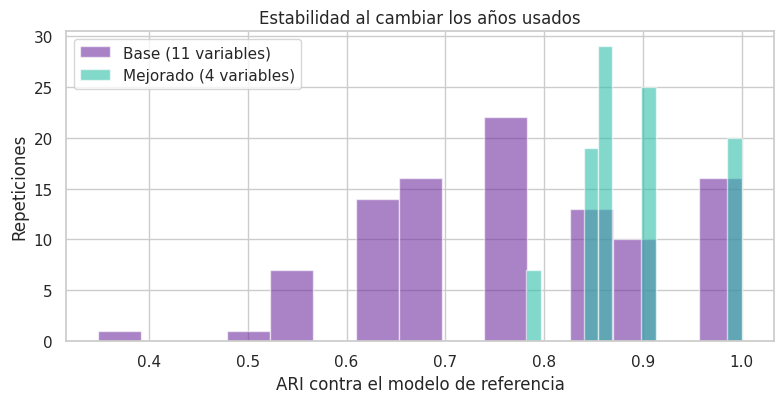

,ARI semillas (media),ARI períodos (media),ARI períodos (mínimo)
Base (11 variables),0.858,0.769,0.349
Mejorado (4 variables),1.000,0.893,0.782


In [20]:
anios = sorted(d.anio.unique())

def estabilidad(preparar, k, n_rep=100):
    # preparar: función que recibe el perfil promedio de grados y devuelve la matriz escalada
    base = preparar(d.groupby("jur")[grados].mean())
    ref = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(base)

    ari_sem = [adjusted_rand_score(ref, KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(base))
               for s in range(30)]

    rng = np.random.default_rng(RANDOM_STATE)
    ari_per = []
    for _ in range(n_rep):
        elegidos = rng.choice(anios, size=8, replace=False)
        p = d[d.anio.isin(elegidos)].groupby("jur")[grados].mean().reindex(perfil.index)
        etiq = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(preparar(p))
        ari_per.append(adjusted_rand_score(ref, etiq))
    return ari_sem, ari_per

prep_base = lambda g: StandardScaler().fit_transform(g[grados])
prep_mejor = lambda g: StandardScaler().fit_transform(resumir(g))

sem_b, per_b = estabilidad(prep_base, 3)
sem_m, per_m = estabilidad(prep_mejor, 3)

tabla_est = pd.DataFrame({
    "ARI semillas (media)": [np.mean(sem_b), np.mean(sem_m)],
    "ARI períodos (media)": [np.mean(per_b), np.mean(per_m)],
    "ARI períodos (mínimo)": [np.min(per_b), np.min(per_m)],
}, index=["Base (11 variables)", "Mejorado (4 variables)"]).round(3)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(per_b, bins=15, alpha=0.6, color="#7030A0", label="Base (11 variables)")
ax.hist(per_m, bins=15, alpha=0.6, color="#30BEAA", label="Mejorado (4 variables)")
ax.set_xlabel("ARI contra el modelo de referencia")
ax.set_ylabel("Repeticiones")
ax.set_title("Estabilidad al cambiar los años usados")
ax.legend()
plt.tight_layout()
plt.show()

tabla_est

El modelo mejorado es **más estable**:

* Con las 11 variables, al cambiar los años usados, el peor caso es un ARI de **0.35**: los grupos casi se reordenan por completo. Con 4 variables, el peor caso es **0.78**.
* Cambiar la semilla no altera nada en el modelo mejorado (ARI = 1.0).

Una explicación probable es que, con menos columnas repetidas, un grado de primaria ruidoso ya no puede torcer el resultado. Esto es una hipótesis razonable, no algo que probamos por separado.

### 4.5 Decisión final

| Criterio | Base (11 variables) | PCA | **Mejorado (4 variables)** |
|---|---|---|---|
| Silhouette en el espacio original | 0.277 | 0.277 | 0.269 |
| Silhouette en su propio espacio | 0.277 | - | **0.379** |
| Estabilidad por semilla (ARI) | 0.86 | - | **1.00** |
| Estabilidad por período (ARI, peor caso) | 0.35 | - | **0.78** |
| Interpretabilidad | Media | Baja (componentes) | **Alta (variables educativas)** |

**Modelo final: K-Means con k = 3 sobre las 4 variables resumidas.** La calidad estadística en el espacio original es equivalente, pero gana claramente en estabilidad e interpretabilidad, que son nuestros otros dos criterios. Descartamos PCA (no aporta) y DBSCAN (frágil con 24 puntos). Ward queda como validación: llega a un resultado muy parecido.

## Parte 5: Modelo final e interpretación de los clusters

In [21]:
perfil_r["cluster"] = etiq_km
perfil["cluster"] = etiq_km

resumen = perfil.groupby("cluster")[grados].mean().round(1)
resumen["Jurisdicciones"] = perfil.groupby("cluster").size()
resumen

,Prim_1,Prim_2,Prim_3,Prim_4,Prim_5,Prim_6,Sec_8,Sec_9,Sec_10,Sec_11,Sec_12,Jurisdicciones
cluster,,,,,,,,,,,,
0,99.3,98.2,97.8,98.2,98.0,98.7,85.7,86.0,85.7,90.2,79.4,6
1,99.5,98.0,97.3,97.7,97.4,98.2,79.0,79.8,80.6,85.1,75.0,12
2,97.0,93.4,92.8,93.2,93.4,95.8,77.7,79.1,80.0,87.2,84.8,6


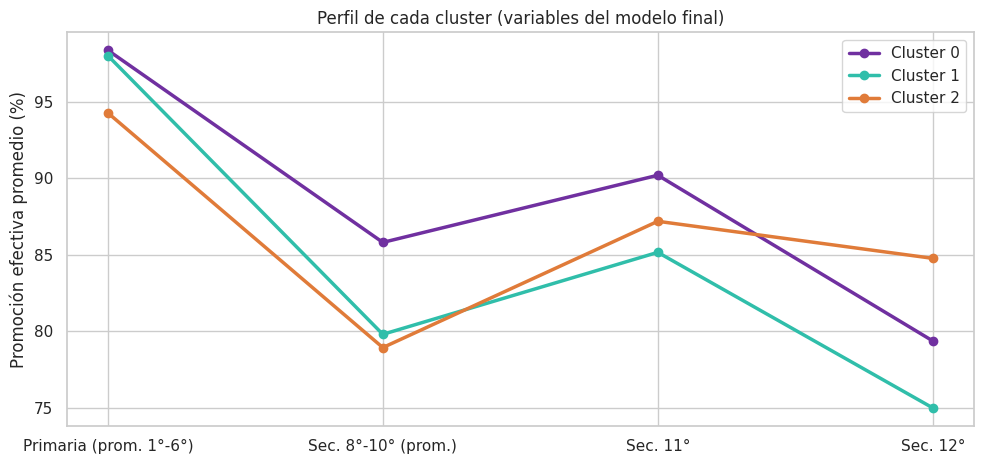

,Primaria (prom. 1°-6°),Sec. 8°-10° (prom.),Sec. 11°,Sec. 12°
cluster,,,,
0,98.4,85.8,90.2,79.4
1,98.0,79.8,85.1,75.0
2,94.3,78.9,87.2,84.8


In [22]:
fig, ax = plt.subplots(figsize=(10, 4.8))
colores_c = {0: "#7030A0", 1: "#30BEAA", 2: "#E07B39"}
medias_r = perfil_r.groupby("cluster").mean()
for c, fila in medias_r.iterrows():
    ax.plot(medias_r.columns, fila.values, marker="o", linewidth=2.5, color=colores_c[c], label=f"Cluster {c}")
ax.set_ylabel("Promoción efectiva promedio (%)")
ax.set_title("Perfil de cada cluster (variables del modelo final)")
ax.legend()
plt.tight_layout()
plt.show()

medias_r.round(1)

In [23]:
for c, g in perfil.groupby("cluster"):
    print(f"Cluster {c} ({len(g)}):", ", ".join(sorted(g.index)))
    print()

Cluster 0 (6): Catamarca, Ciudad de Buenos Aires, Cordoba, La Rioja, Tierra Del Fuego, Tucumán

Cluster 1 (12): Buenos Aires, Chaco, Chubut, Formosa, Jujuy, La Pampa, Mendoza, Neuquén, Rio Negro, Salta, Santa Cruz, Santa Fe

Cluster 2 (6): Corrientes, Entre Rios, Misiones, San Juan, San Luis, Santiago Del Estero



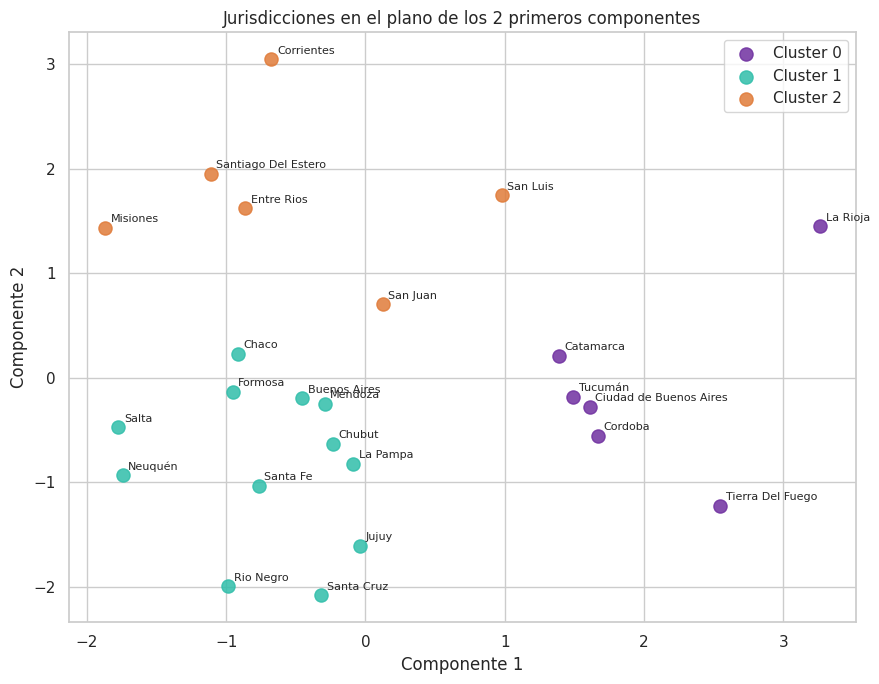

In [24]:
# Visualización en 2 dimensiones (PCA solo para dibujar)
P2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_r)

plt.figure(figsize=(9, 7))
for c in sorted(perfil.cluster.unique()):
    m = (perfil.cluster == c).values
    plt.scatter(P2[m, 0], P2[m, 1], s=90, color=colores_c[c], label=f"Cluster {c}", alpha=0.85)
for i, nombre in enumerate(perfil.index):
    plt.annotate(nombre, (P2[i, 0], P2[i, 1]), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.title("Jurisdicciones en el plano de los 2 primeros componentes")
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
# Silhouette por jurisdicción en el modelo final
perfil["silhouette"] = silhouette_samples(X_r, etiq_km)
print("Silhouette del modelo final:", round(silhouette_score(X_r, etiq_km), 3))
print("Jurisdicciones con silhouette < 0.1 (frontera entre grupos):")
print(perfil[perfil.silhouette < 0.1][["cluster", "silhouette"]].round(2).to_string())

Silhouette del modelo final: 0.379
Jurisdicciones con silhouette < 0.1 (frontera entre grupos):
          cluster  silhouette
jur                          
San Juan        2        0.06
San Luis        2       -0.00


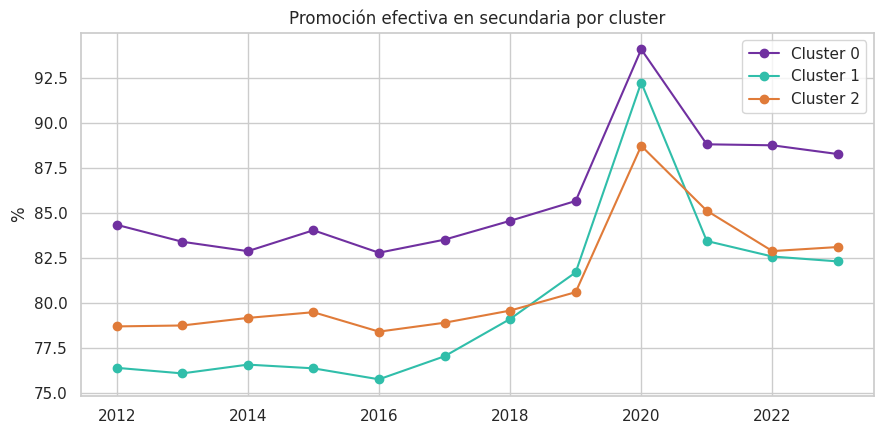

In [26]:
# ¿Cómo evolucionó cada cluster en el tiempo? (secundaria)
mapa = perfil.cluster.to_dict()
d_c = d.assign(cluster=d.jur.map(mapa))
evol = d_c.groupby(["anio", "cluster"]).Sec_Total.mean().unstack()

fig, ax = plt.subplots(figsize=(9, 4.5))
for c in evol.columns:
    ax.plot(evol.index, evol[c], marker="o", color=colores_c[c], label=f"Cluster {c}")
ax.set_title("Promoción efectiva en secundaria por cluster")
ax.set_ylabel("%")
ax.legend()
plt.tight_layout()
plt.show()

**Cómo leer los tres grupos** :

* **Cluster 0, "secundaria inicial fuerte" (6):** Catamarca, Ciudad de Buenos Aires, Córdoba, La Rioja, Tierra del Fuego y Tucumán. Tienen la promoción **más alta** en primaria (98.4%), en 8° a 10° (85.8%) y en 11° (90.2%), con 12° intermedio (79.4%).
* **Cluster 1, "primaria sólida, secundaria con más dificultad" (12):** Buenos Aires, Chaco, Chubut, Formosa, Jujuy, La Pampa, Mendoza, Neuquén, Río Negro, Salta, Santa Cruz y Santa Fe. Primaria alta (98.0%), pero secundaria más baja (79.8% en 8° a 10°) y el **12° más bajo de todos (75.0%)**. Es el grupo más grande.
* **Cluster 2, "primaria más baja, pero 12° alto" (6):** Corrientes, Entre Ríos, Misiones, San Juan, San Luis y Santiago del Estero. Tienen la **primaria más baja** (94.3%) y 8° a 10° también bajo (78.9%), pero el **12° más alto** (84.8%).

**Qué nos dice el modelo:**

* **La geografía no alcanza para explicar los grupos.** El cluster 1 mezcla provincias patagónicas, del noroeste, del noreste y del centro del país.
* **El cluster 2 es el menos cohesivo** (silhouette promedio 0.28, contra 0.42 y 0.41 de los otros). San Juan (0.06) y San Luis (0.00) están en la frontera con otros grupos: conviene leerlas como casos intermedios, no como miembros claros.
* **El patrón del cluster 2 es llamativo:** primaria baja y 12° alto. Coincide con la correlación negativa entre primaria y 12° que vimos en el AED. Una **hipótesis a verificar** (no probada con estos datos) es que en 12° ya solo queda quien llegó hasta ahí, así que la promoción de ese año no refleja a quienes abandonaron antes. Se podría chequear con indicadores de abandono o de trayectoria.
* **En el tiempo:** los tres grupos tienen su pico en 2020 y después bajan, aunque quedan por encima de su nivel previo. El cluster 0 se mantiene arriba y el cluster 1 abajo en secundaria; la brecha se achica algo, pero persiste (por ejemplo, 84.3% contra 76.4% en 2012 y 88.3% contra 82.3% en 2023).

## Parte 6: Conclusiones y limitaciones

**Respuesta a la pregunta:** sí, hay tres perfiles de jurisdicciones según su promoción efectiva, pero con **fronteras suaves**: el silhouette final es moderado (0.38) y algunas jurisdicciones quedan entre dos grupos.

**Qué hicimos y por qué (criterio explícito):**

1. **AED:** detectamos los agregados que se superponen, los nulos estructurales (7° año), los valores mayores a 100 y la redundancia entre grados de primaria.
2. **Modelo base:** K-Means con k=3, elegido por silhouette, Davies-Bouldin e interpretabilidad (silhouette 0.277).
3. **Mejora:** descartamos PCA (sin ganancia), comparamos con Ward y DBSCAN (coinciden en lo grueso; DBSCAN es frágil con 24 puntos) y **resumimos las 11 variables en 4**, lo que hizo al modelo mucho más estable (peor caso de estabilidad por período de 0.35 a 0.78) y más fácil de interpretar.

**Limitaciones:**

* **Pocos datos:** son 24 jurisdicciones. Los resultados son exploratorios y un cambio chico puede mover a una provincia de grupo.
* **Silhouette moderado y un cluster poco cohesivo** (el 2), con dos jurisdicciones en la frontera.
* **El promedio 2012-2023 esconde la dinámica** y mezcla el año atípico de 2020. La prueba de estabilidad por período mitiga el problema, pero no lo elimina.
* **La agrupación de grados en 4 variables es una decisión nuestra**, basada en el AED. Otra agrupación podría dar grupos algo distintos.
* **La promoción efectiva no mide abandono ni calidad:** un valor alto no significa necesariamente mejor educación. Las hipótesis de la Parte 5 deberían validarse con otros indicadores.
* Los valores mayores a 100 se dejaron sin modificar.

**Próximos pasos posibles:** repetir el análisis con la unidad provincia-año (288 filas), sumar indicadores de abandono, repitencia y sobreedad, y contrastar los grupos con otras fuentes.